# 🏔️ Arctic Sentinel AI: Route Risk Analysis & Intelligence Model

## 📌 Project Overview
This model is an **AI-Powered Route Intelligence System** specifically designed for the Arctic and extreme-weather regions (such as Yakutsk, Magadan, and Svalbard). Its primary objective is to analyze safe routes for travelers and communities, providing critical alerts about potential hazards in extreme conditions.

The system calculates the optimal path between **Start** and **End** locations and computes real-time risk probabilities for various coordinates along the journey.

## 🚀 Core Capabilities & Features
* **Dynamic Route Generation:** Utilizes OSRM (Open Source Routing Machine) to generate a continuous and highly accurate path from origin to destination.
* **Risk Assessment Engine:** Analyzes weather APIs and geographical parameters to assign a precise Risk Percentage to individual points along the route.
* **Zone Categorization:** Smartly classifies risk into 3 distinct tiers:
  * 🟢 **Low Risk** (0-35%)
  * 🟡 **Medium Risk** (36-55%)
  * 🔴 **High Risk** (56-100%)
* **Interactive Geo-Visualization:** Plots the processed data onto a full-screen interactive map using Leaflet.js and OpenStreetMap, complete with real-time user device location (GPS) tracking.

## 🛠️ Technology Stack
* **Backend Engine:** FastAPI (Python) for high-performance, rapid API responses.
* **Routing & Data:** OSRM, OpenWeather API, and SQLite (for administrative search logging).
* **Frontend Visualization:** HTML5, CSS3, Vanilla JavaScript, and Leaflet.js.
* **Data Flow:** Browser `Render Clouds` for instant, zero-latency state transfer between the main dashboard and the full-screen map view.

## 🎯 Objective of this Notebook
This notebook demonstrates the core logic, data processing pipelines, API integrations, and overall backend architecture of the route-risk assessment model, providing a comprehensive deep dive into how the system engine operates.

# Import requested Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

# Mount Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Read the data and Check top 5 records
column 0 = Safe

and 1 = unsafe

In [ ]:
data = pd.read_csv('/content/drive/MyDrive/Shiva/arctic_scraped_data.csv')
data.head()

,temp,snowfall,precip,wind,Latitude,Longitude,Risk_Label,Wind_Chill,Is_Freezing,Severe_Weather,Risk_Zone,Zone_Weather_Risk,Is_Night,Is_RushHour,START_DT_UTC,Visibility_m,Snow_Depth_m,Surface_Pressure_hPa,Black_Ice_Risk
0,17.2,0.0,0.0,10.5,51.015001,-114.005256,1,17.181216,0,0,4,0,1,0,2026-09-18 21:36:31,10000.0,0.0,902.20,0.0
1,10.7,0.0,0.9,12.0,51.015001,-114.005256,0,9.162791,0,0,4,0,1,0,2026-09-18 22:24:28,10000.0,0.0,901.70,0.0
2,9.1,0.0,0.0,6.5,51.048696,-114.073678,0,8.303608,0,0,0,0,1,0,2026-09-18 22:23:12,10000.0,0.0,1013.25,0.0
3,6.0,0.0,0.0,10.5,51.139582,-113.974927,1,3.751202,0,0,2,0,1,0,2026-09-18 23:31:40,10000.0,0.0,897.20,0.0
4,12.6,0.0,0.0,9.4,51.139582,-113.974927,0,11.828285,0,0,2,0,1,0,2026-09-19 00:07:43,10000.0,0.0,896.70,0.0


# To Check data type

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3934 entries, 0 to 3933
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   temp                  3934 non-null   float64
 1   snowfall              3934 non-null   float64
 2   precip                3934 non-null   float64
 3   wind                  3934 non-null   float64
 4   Latitude              3934 non-null   float64
 5   Longitude             3934 non-null   float64
 6   Risk_Label            3934 non-null   int64  
 7   Wind_Chill            3934 non-null   float64
 8   Is_Freezing           3934 non-null   int64  
 9   Severe_Weather        3934 non-null   int64  
 10  Risk_Zone             3934 non-null   int64  
 11  Zone_Weather_Risk     3934 non-null   int64  
 12  Is_Night              3934 non-null   int64  
 13  Is_RushHour           3934 non-null   int64  
 14  START_DT_UTC          3934 non-null   object 
 15  Visibility_m         

# 5 points summary data

In [ ]:
data.describe()

,temp,snowfall,precip,wind,Latitude,Longitude,Risk_Label,Wind_Chill,Is_Freezing,Severe_Weather,Risk_Zone,Zone_Weather_Risk,Is_Night,Is_RushHour,Visibility_m,Snow_Depth_m,Surface_Pressure_hPa,Black_Ice_Risk
count,3934.000000,3934.000000,3934.000000,3934.000000,3934.000000,3934.000000,3934.000000,3934.000000,3934.000000,3934.000000,3934.000000,3934.000000,3934.000000,3934.000000,3934.000000,3934.000000,3934.000000,3934.000000
mean,2.387748,0.012011,0.052262,9.770793,51.040430,-114.050517,0.478648,-0.020667,0.422979,0.097865,3.881037,0.359939,0.679461,0.183528,9341.128622,0.054809,892.378266,0.266650
std,12.512531,0.063428,0.293430,4.701454,0.069780,0.070176,0.499607,14.555156,0.494095,0.297169,2.847793,1.375970,0.466743,0.387148,2318.093711,0.099721,16.530123,0.442264
min,-36.300000,0.000000,0.000000,0.200000,50.856502,-114.281108,0.000000,-47.140627,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1000.000000,0.000000,845.200000,0.000000
25%,-5.300000,0.000000,0.000000,6.500000,50.996088,-114.094733,0.000000,-8.932685,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,10000.000000,0.000000,885.600000,0.000000
50%,2.100000,0.000000,0.000000,9.500000,51.046958,-114.049399,0.000000,-0.472882,0.000000,0.000000,4.000000,0.000000,1.000000,0.000000,10000.000000,0.000000,891.900000,0.000000
75%,11.900000,0.000000,0.000000,12.300000,51.086705,-114.001673,1.000000,11.019965,1.000000,0.000000,6.000000,0.000000,1.000000,0.000000,10000.000000,0.070000,897.200000,1.000000
max,33.300000,1.890000,7.300000,38.600000,51.184097,-113.882874,1.000000,36.599732,1.000000,1.000000,9.000000,9.000000,1.000000,1.000000,10000.000000,0.510000,1013.250000,1.000000


# Check Null Values

In [ ]:
data.isnull().sum()

,0
temp,0
snowfall,0
precip,0
wind,0
Latitude,0
Longitude,0
Risk_Label,0
Wind_Chill,0
Is_Freezing,0
Severe_Weather,0


# Check Duplicate Values

In [ ]:
data.duplicated().sum()

np.int64(0)

# Check Row and Columns

In [ ]:
data.shape

(3934, 19)

column = 0 = Safe
and 1 = unsafe

# Numerical Features Distribution
Generates histograms with KDE curves to visualize the distribution, spread, and skewness of numerical weather features.

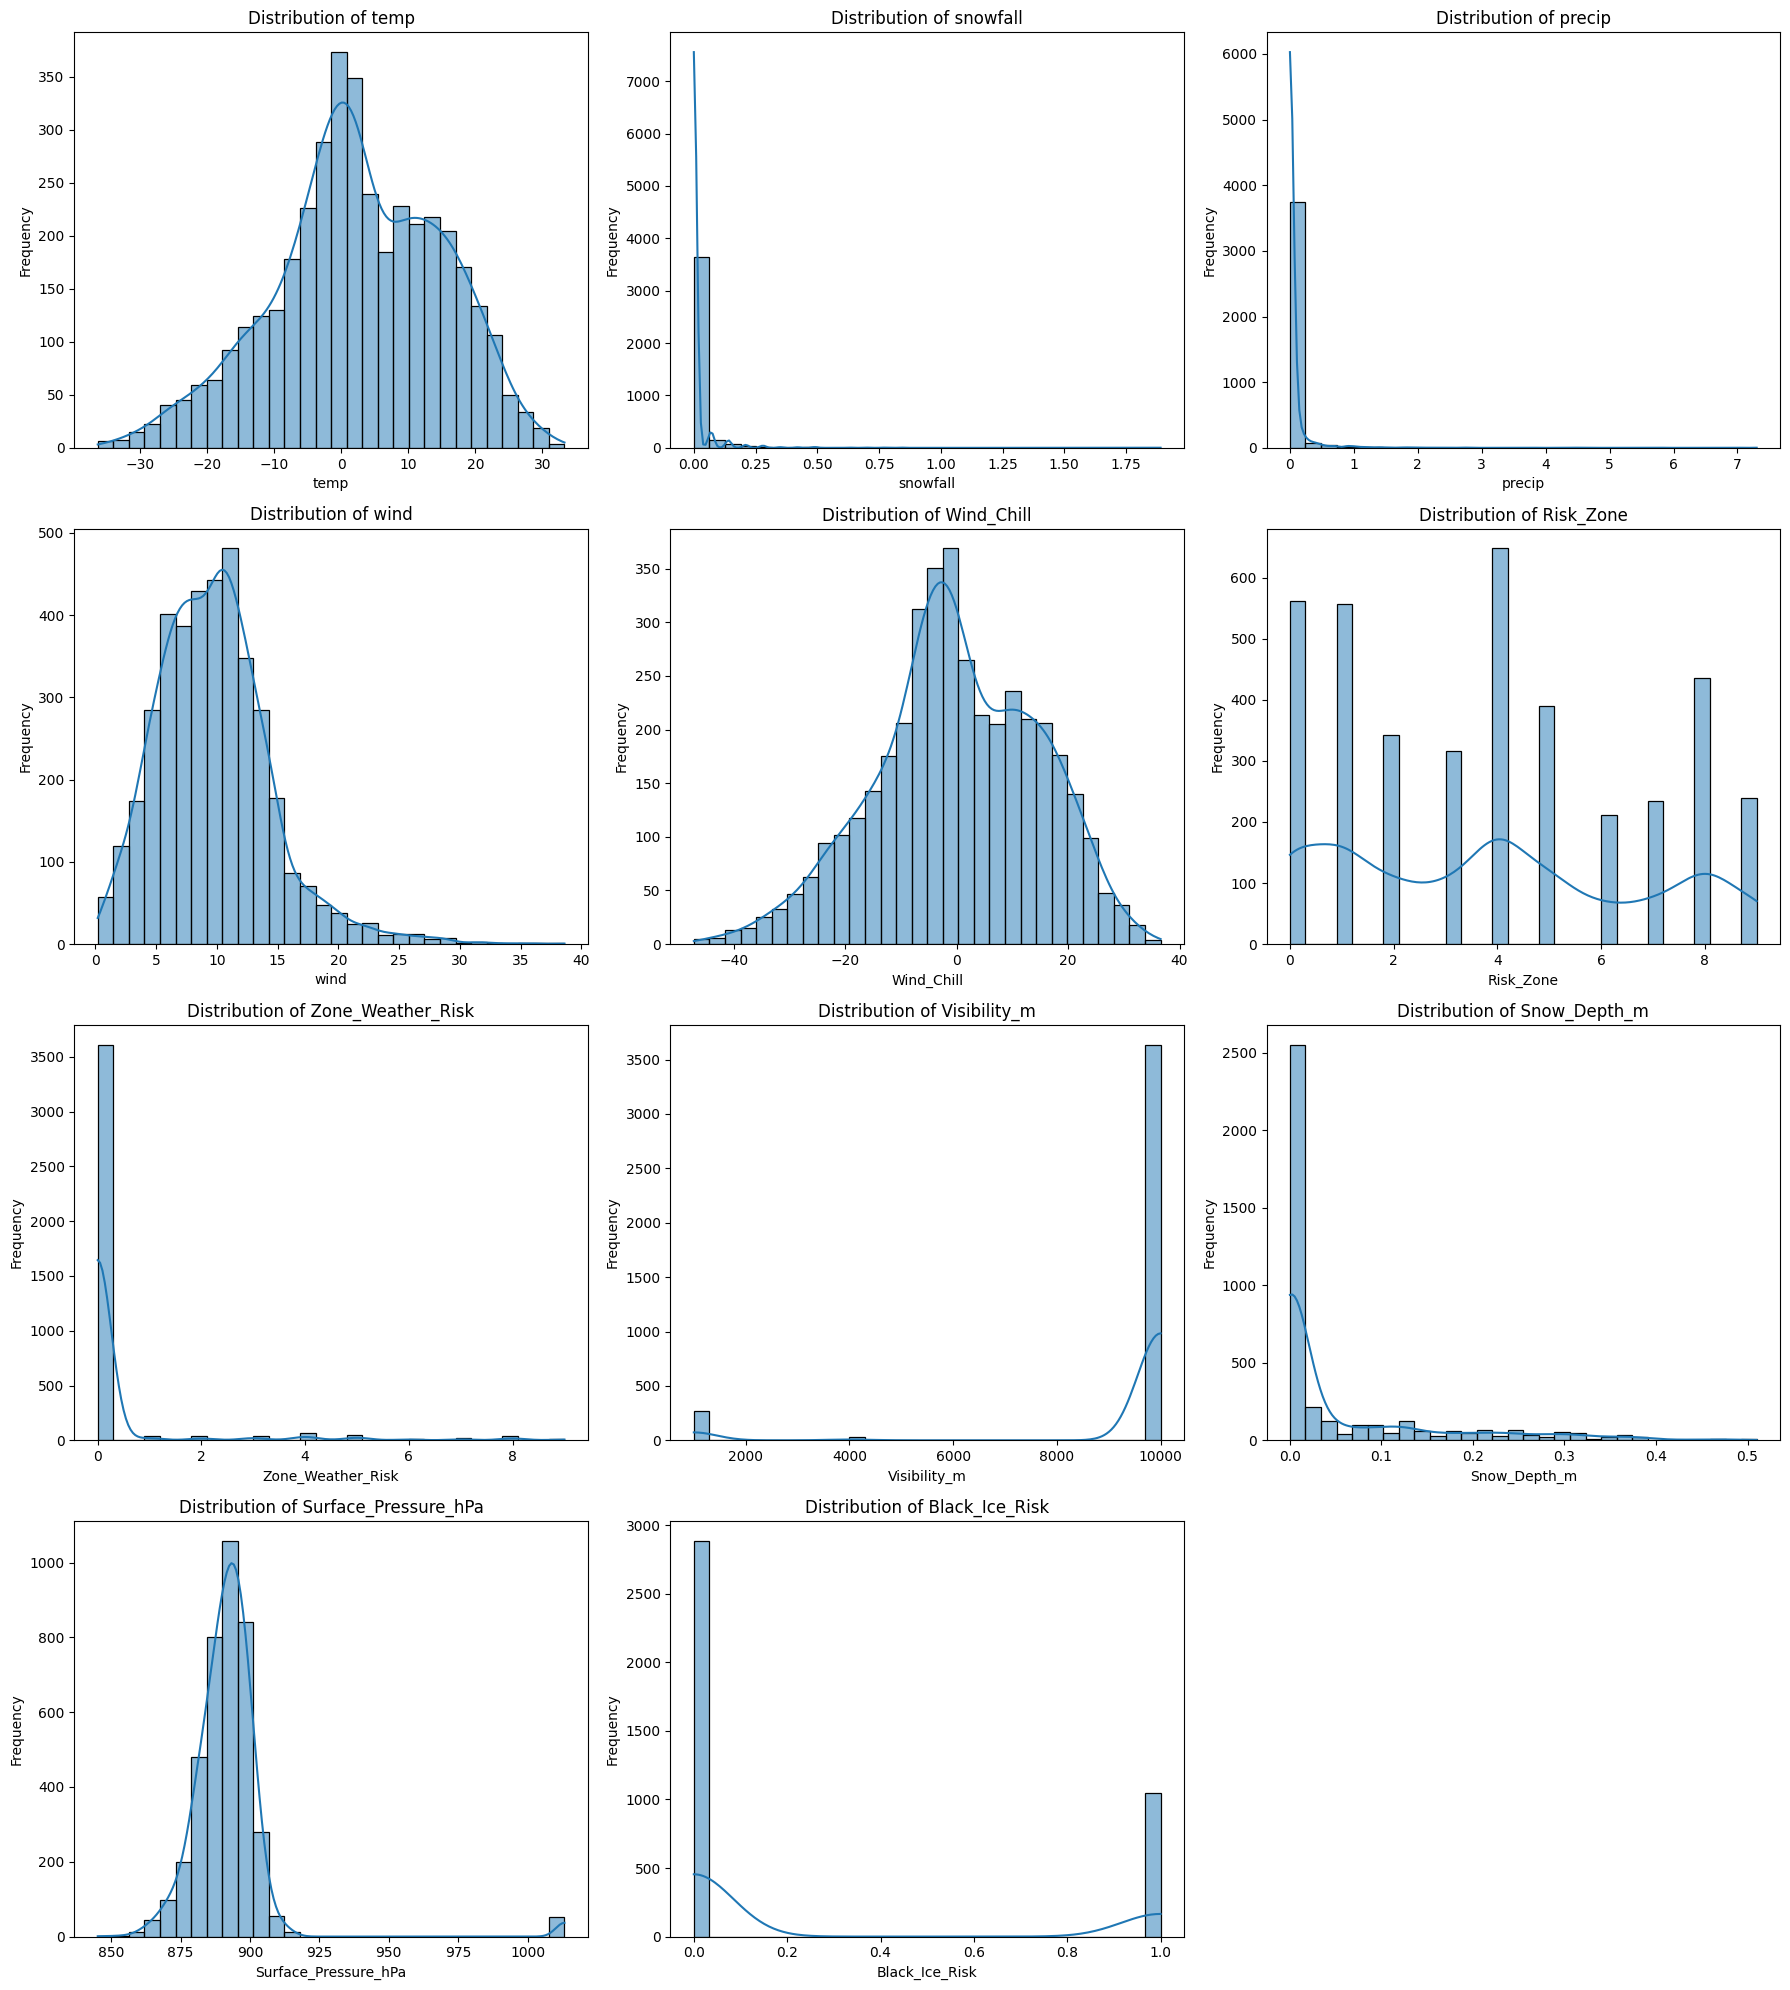

In [ ]:
# Select numerical columns from the dataset
numerical_cols = data.select_dtypes(include="number").columns.tolist()

# Exclude columns reserved for separate EDA graphs
exclude_cols = ["Latitude", "Longitude", "Risk_Label", "Is_Freezing", "Severe_Weather", "Is_Night", "Is_RushHour"]
plot_cols = [col for col in numerical_cols if col not in exclude_cols]

# Calculate subplot layout based on the number of features
if not plot_cols:
    print("No numerical features available for plotting.")
else:
    ncols = 3
    nrows = math.ceil(len(plot_cols) / ncols)

    # Create a grid of plots
    fig, axes = plt.subplots(nrows, ncols, figsize=(18, 5 * nrows))
    axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

    # Generate a histogram with KDE for each numerical feature
    for i, col in enumerate(plot_cols):
        values = data[col].dropna()

        # Hide plots for columns containing only missing values
        if values.empty:
            axes[i].set_visible(False)
            continue

        # Plot feature distribution and density curve
        sns.histplot(values, bins=30, kde=True, ax=axes[i])
        axes[i].set_title(f"Distribution of {col}")
        axes[i].set_xlabel(col)
        axes[i].set_ylabel("Frequency")

    # Hide unused subplot spaces
    for i in range(len(plot_cols), len(axes)):
        axes[i].set_visible(False)

    # Adjust spacing and display all graphs
    plt.tight_layout()
    plt.show()

# Outlier Detection Boxplots
Visualizes the temperature distribution and highlights potential outliers.

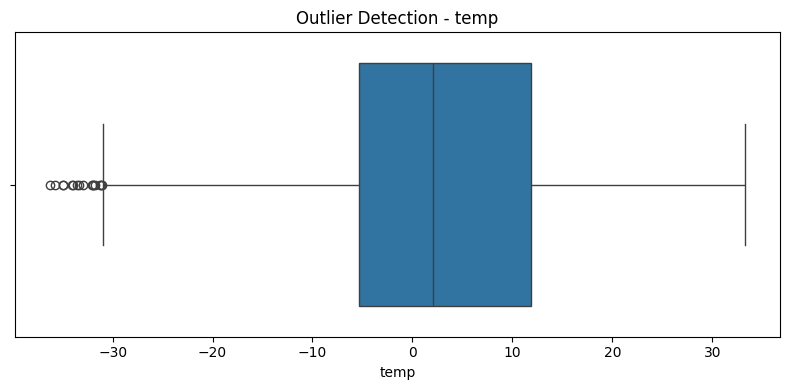

In [ ]:
# Select temperature values and remove missing entries
col = "temp"
values = data[col].dropna()

# Generate boxplot for temperature
plt.figure(figsize=(8, 4))
sns.boxplot(x=values)
plt.title(f"Outlier Detection - {col}")
plt.xlabel(col)
plt.tight_layout()
plt.show()

# Identifies potential outliers in snowfall measurements.

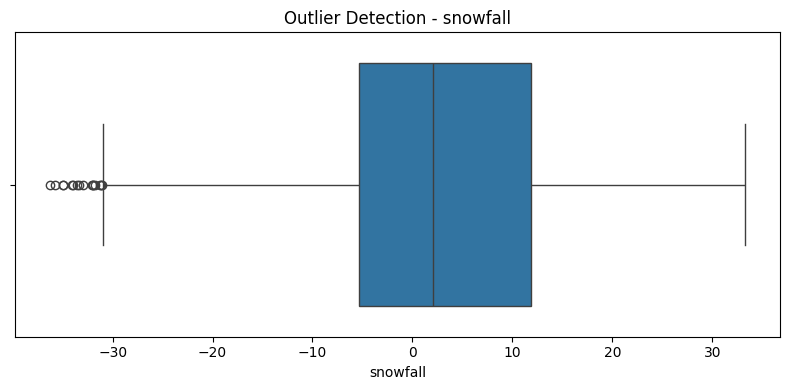

In [ ]:
# Select snowfall values
col = "snowfall"
# Generate boxplot for snowfall
plt.figure(figsize=(8, 4))
sns.boxplot(x=values)
plt.title(f"Outlier Detection - {col}")
plt.xlabel(col)
plt.tight_layout()
plt.show()

# Highlights the spread and potential outliers in precipitation values.

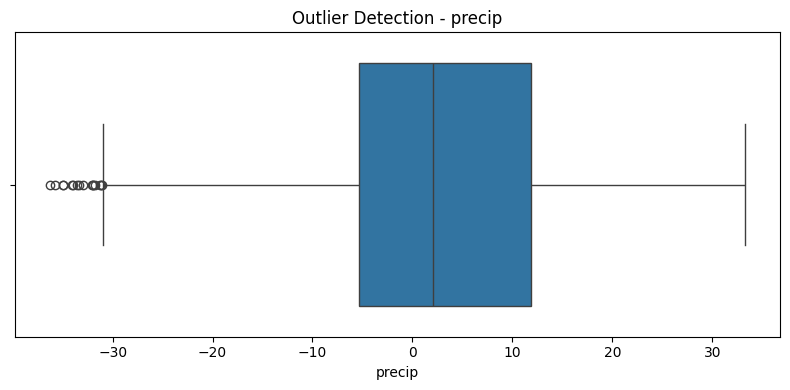

In [ ]:
# Select precipitation values
col = "precip"

# Generate boxplot for precipitation
plt.figure(figsize=(8, 4))
sns.boxplot(x=values)
plt.title(f"Outlier Detection - {col}")
plt.xlabel(col)
plt.tight_layout()
plt.show()

# Snowfall Values Detailed Distribution
Displays the frequency distribution of snowfall values to reveal the concentration near zero and the spread of higher values.

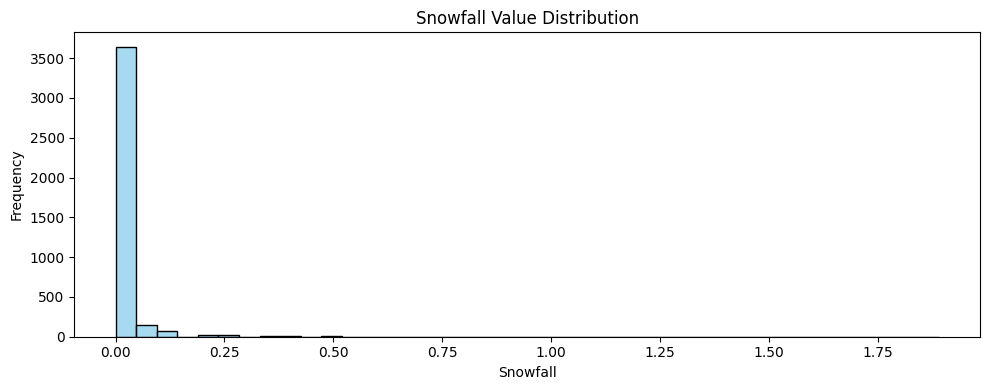

In [ ]:
# Create a frequency histogram of snowfall values
plt.figure(figsize=(10, 4))
sns.histplot(data=data, x="snowfall", bins=40, color="skyblue")

# Add labels and display the graph
plt.title("Snowfall Value Distribution")
plt.xlabel("Snowfall")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# Precipition Values Detailed Distribution

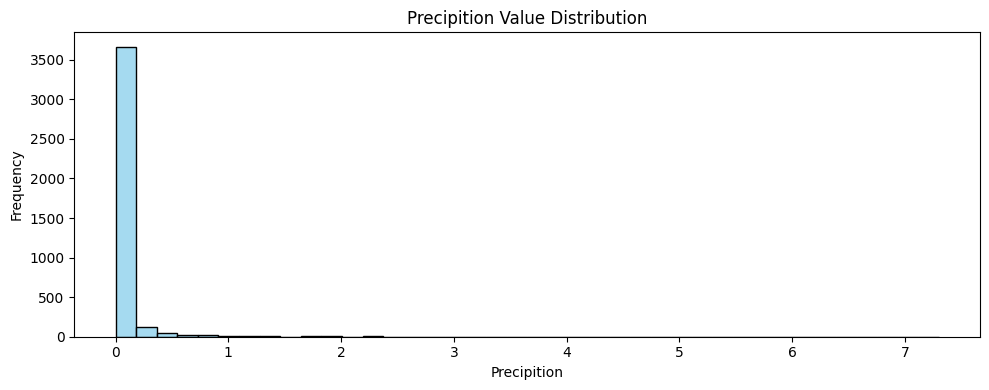

In [ ]:
# Create a frequency histogram of preciption values
plt.figure(figsize=(10, 4))
sns.histplot(data=data, x="precip", bins=40, color="skyblue")

# Add labels and display the graph
plt.title("Precipition Value Distribution")
plt.xlabel("Precipition")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# Create a count plot for each Risk_Label category
Visualizes the frequency of each Risk_Label category to understand the distribution of risk classes and identify potential class imbalance

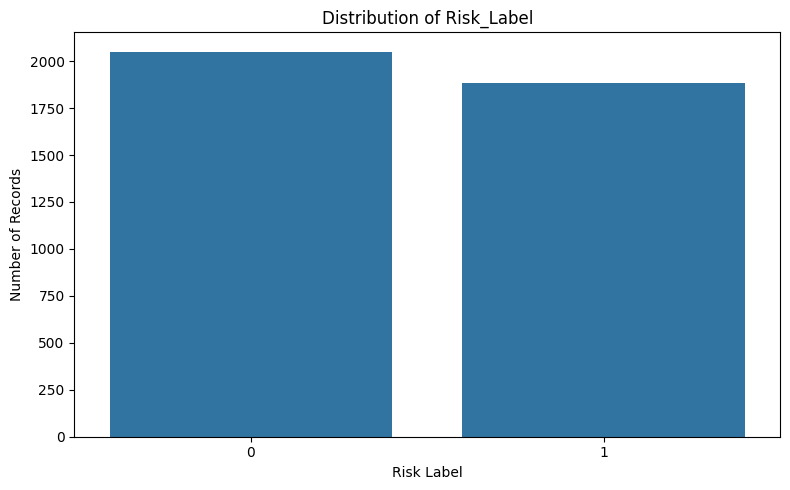

In [ ]:
# Create a count plot for each Risk_Label category
plt.figure(figsize=(8, 5))
sns.countplot(data=data, x="Risk_Label")

# Add graph title and axis labels
plt.title("Distribution of Risk_Label")
plt.xlabel("Risk Label")
plt.ylabel("Number of Records")

# Display the graph
plt.tight_layout()
plt.show()

# Categorical Features Count Plots
Shows the count of records for each freezing-status category

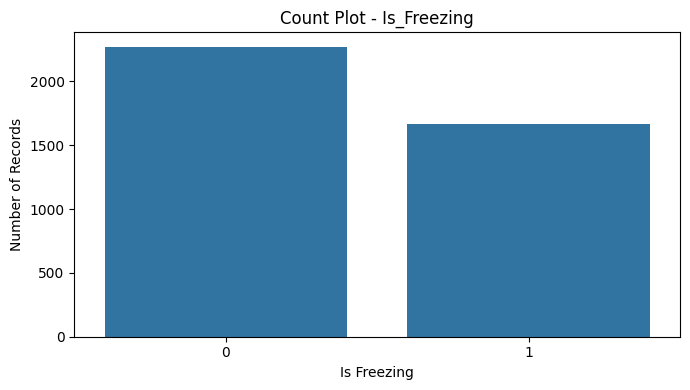

In [ ]:
# Plot the frequency of each Is_Freezing category
plt.figure(figsize=(7, 4))
sns.countplot(data=data, x="Is_Freezing")

# Add title and axis labels
plt.title("Count Plot - Is_Freezing")
plt.xlabel("Is Freezing")
plt.ylabel("Number of Records")

# Display the graph
plt.tight_layout()
plt.show()

# Compares the frequency of severe-weather categories.

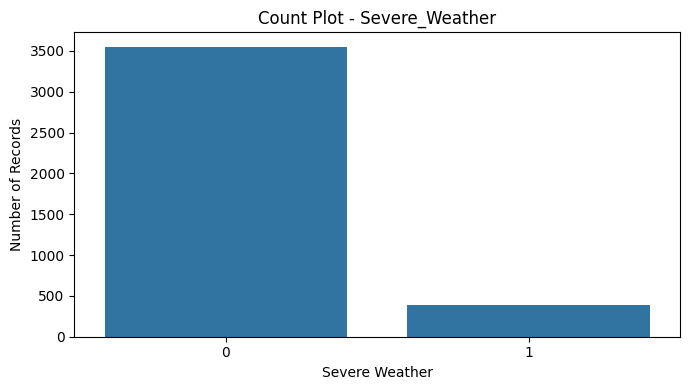

In [ ]:
# Plot the frequency of each Severe_Weather category
plt.figure(figsize=(7, 4))
sns.countplot(data=data, x="Severe_Weather")

# Add title and axis labels
plt.title("Count Plot - Severe_Weather")
plt.xlabel("Severe Weather")
plt.ylabel("Number of Records")

# Display the graph
plt.tight_layout()
plt.show()

# Shows how records are distributed between day and night categories.

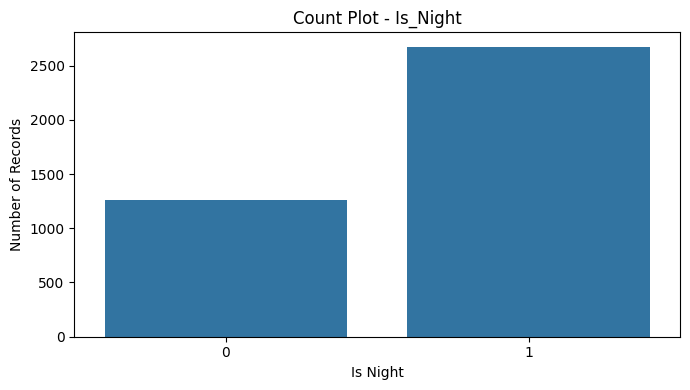

In [ ]:
# Plot the frequency of day and night records
plt.figure(figsize=(7, 4))
sns.countplot(data=data, x="Is_Night")

# Add title and axis labels
plt.title("Count Plot - Is_Night")
plt.xlabel("Is Night")
plt.ylabel("Number of Records")

# Display the graph
plt.tight_layout()
plt.show()

# Compares the number of records marked as rush hour versus non-rush hour

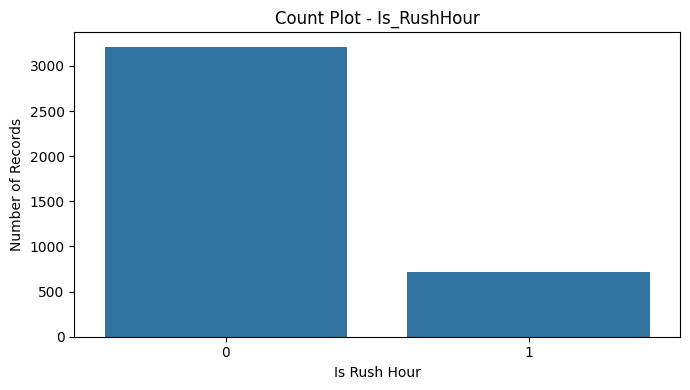

In [ ]:
# Plot the frequency of rush-hour categories
plt.figure(figsize=(7, 4))
sns.countplot(data=data, x="Is_RushHour")

# Add title and axis labels
plt.title("Count Plot - Is_RushHour")
plt.xlabel("Is Rush Hour")
plt.ylabel("Number of Records")

# Display the graph
plt.tight_layout()
plt.show()

# Shows the frequency of each black-ice risk category

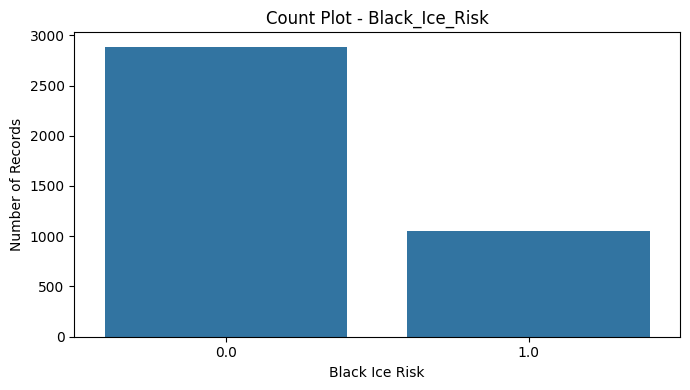

In [ ]:
# Plot the frequency of each Black_Ice_Risk category
plt.figure(figsize=(7, 4))
sns.countplot(data=data, x="Black_Ice_Risk")

# Add title and axis labels
plt.title("Count Plot - Black_Ice_Risk")
plt.xlabel("Black Ice Risk")
plt.ylabel("Number of Records")

# Display the graph
plt.tight_layout()
plt.show()

# Feature Correlation Heatmap
Visualizes pairwise correlations between numerical features. Positive values indicate positive linear relationships, negative values indicate negative linear relationships, and values near zero indicate weak linear relationships.

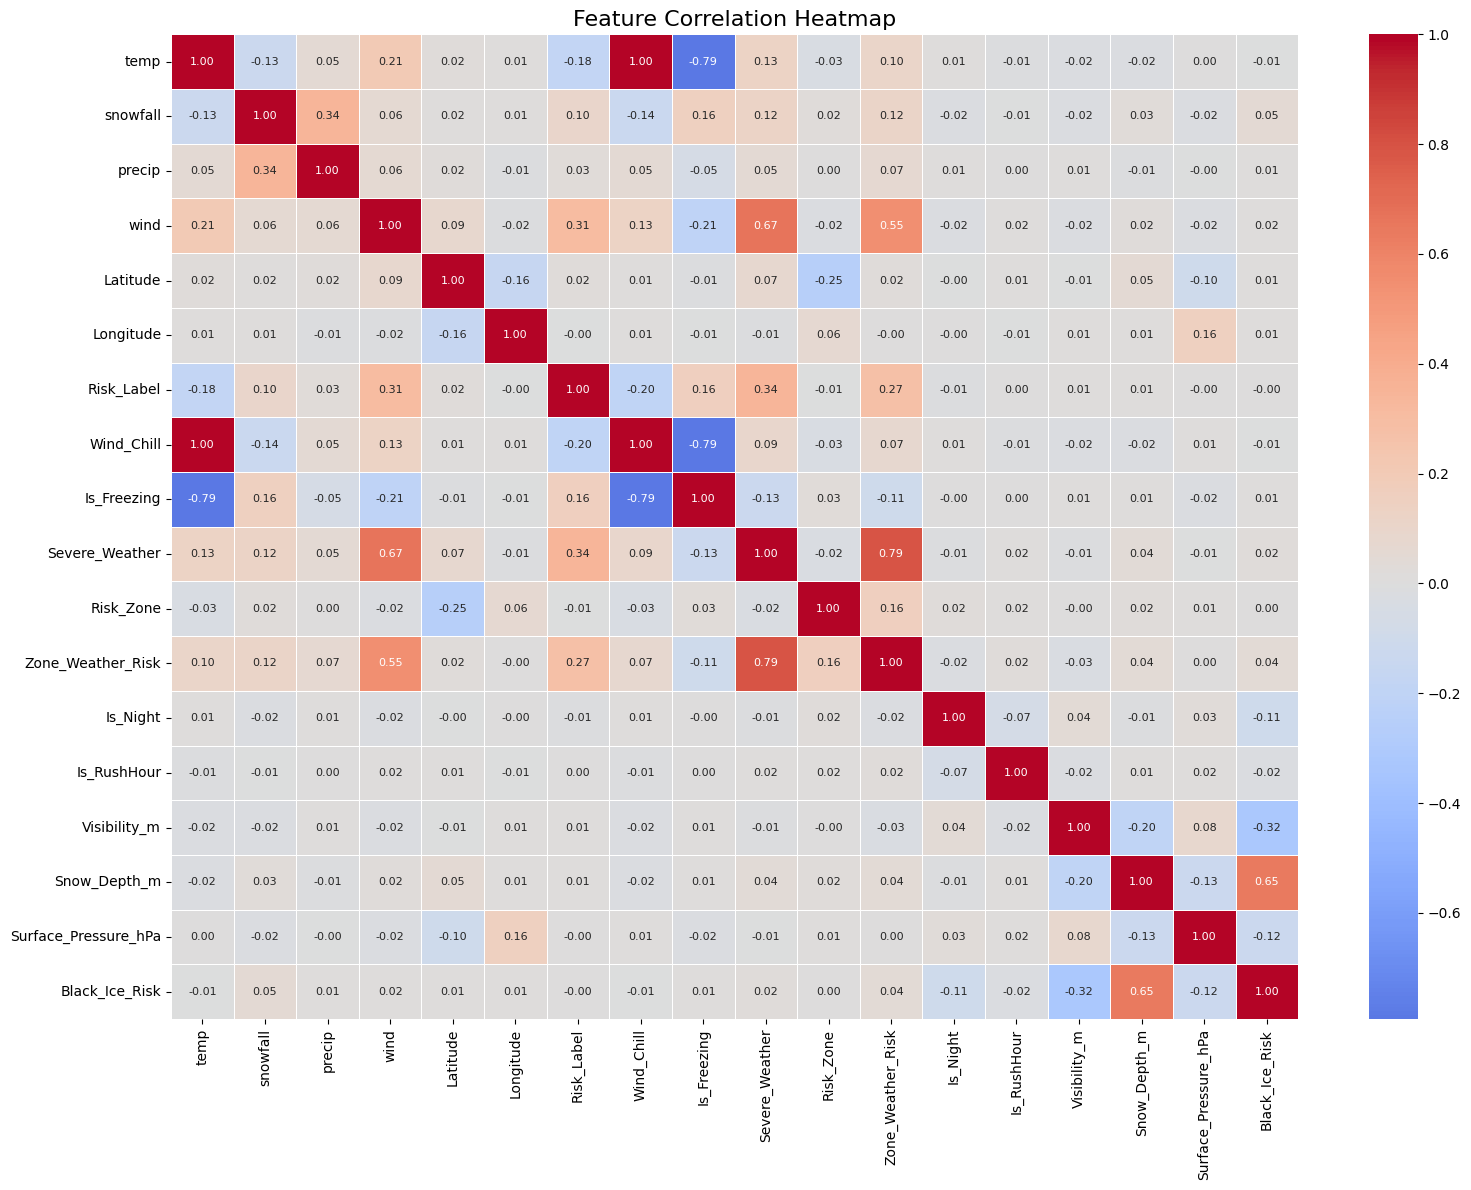

In [ ]:
# Select numerical columns
numerical_data = data.select_dtypes(include="number")

# Calculate pairwise correlations using available observations
correlation_matrix = numerical_data.corr()

# Create the correlation heatmap
plt.figure(figsize=(16, 12))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    annot_kws={"size": 8})

# Add title and adjust layout
plt.title("Feature Correlation Heatmap", fontsize=16)
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()

# Display the graph
plt.show()

# Observation — Feature Correlation Heatmap

The correlation heatmap reveals several important relationships among the weather and risk-related features. The strongest positive correlation is observed between Severe_Weather and Zone_Weather_Risk (0.79), followed by wind and Severe_Weather (0.67), and Snow_Depth_m and Black_Ice_Risk (0.65). Strong negative correlations are observed between temp and Is_Freezing (-0.79), and between Wind_Chill and Is_Freezing (-0.79).

Risk_Label exhibits moderate positive correlations with Severe_Weather (0.34) and wind (0.31). Most other features have relatively weak linear correlations with the target. The near-perfect correlation between temp and Wind_Chill warrants further investigation for potential redundancy. These relationships indicate associations rather than causation, and the definitions of derived risk features should be reviewed to assess potential data leakage.

# Temperature Distribution by Risk Label
Compares temperature distributions, medians, and potential outliers between the two Risk_Label classes.

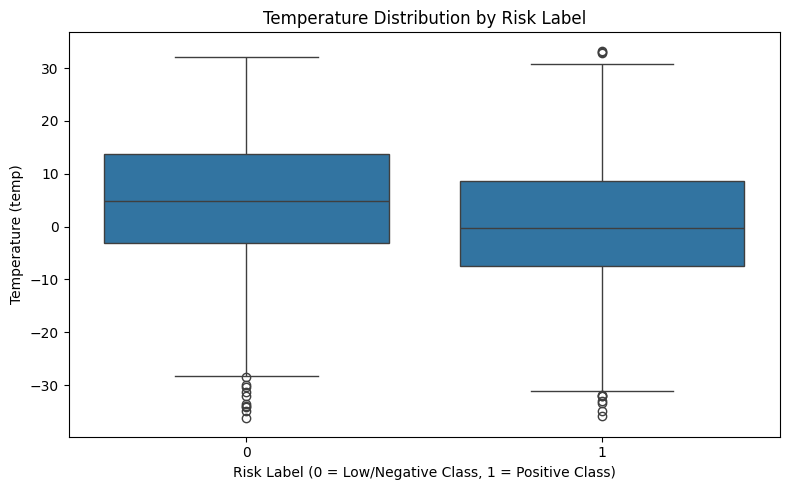

In [ ]:
# Create a boxplot to compare temperature across risk labels
plt.figure(figsize=(8, 5))
sns.boxplot(data=data, x="Risk_Label", y="temp")

# Add graph title and axis labels
plt.title("Temperature Distribution by Risk Label")
plt.xlabel("Risk Label (0 = Low/Negative Class, 1 = Positive Class)")
plt.ylabel("Temperature (temp)")

# Display the graph
plt.tight_layout()
plt.show()

# Combined Weather Features vs Risk Label
Compares the mean standardized values of selected weather features across risk-label classes in a single graph, making differences in feature patterns easier to observe despite different measurement scales.

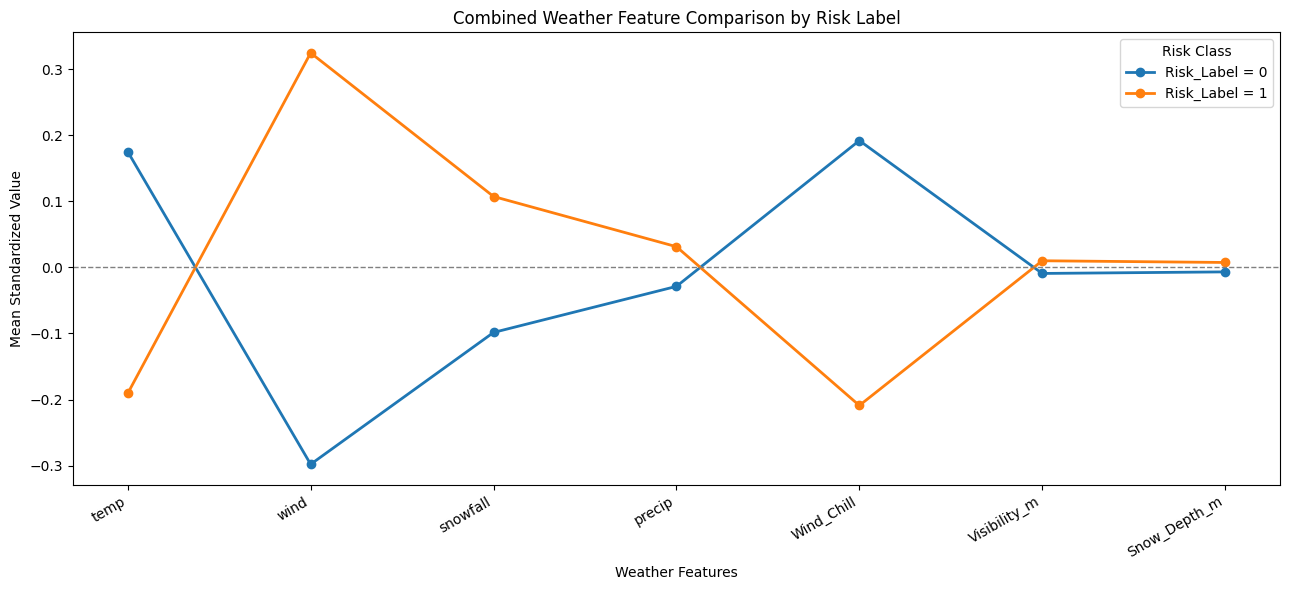

In [ ]:
# Select weather features for comparison
features = ["temp", "wind", "snowfall", "precip", "Wind_Chill", "Visibility_m", "Snow_Depth_m"]

# Calculate temporary standardized values for visualization only
feature_means = data[features].mean()
feature_stds = data[features].std().replace(0, 1)
standardized_data = (data[features] - feature_means) / feature_stds

# Add Risk_Label to a separate temporary visualization DataFrame
plot_data = standardized_data.copy()
plot_data["Risk_Label"] = data["Risk_Label"]

# Calculate mean standardized feature values for each risk class
risk_means = plot_data.groupby("Risk_Label")[features].mean().T

# Plot both risk classes in a single graph
plt.figure(figsize=(13, 6))
for risk_class in risk_means.columns:
    plt.plot(risk_means.index, risk_means[risk_class], marker="o", linewidth=2, label=f"Risk_Label = {risk_class}")

# Add graph title, labels, and reference line
plt.axhline(0, color="gray", linestyle="--", linewidth=1)
plt.title("Combined Weather Feature Comparison by Risk Label")
plt.xlabel("Weather Features")
plt.ylabel("Mean Standardized Value")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Risk Class")
plt.tight_layout()
plt.show()

# Observation:
 Risk_Label 1 shows higher average standardized values for wind and snowfall, while temperature and wind chill have lower values compared with Risk_Label 0. Visibility and snow depth show very little difference in their average values between the two risk classes.

# Temperature vs Black Ice Risk
This overlapping histogram compares temperature distributions for records with and without black ice risk. It helps identify whether the two risk groups tend to occur at different temperatures or have similar distributions.

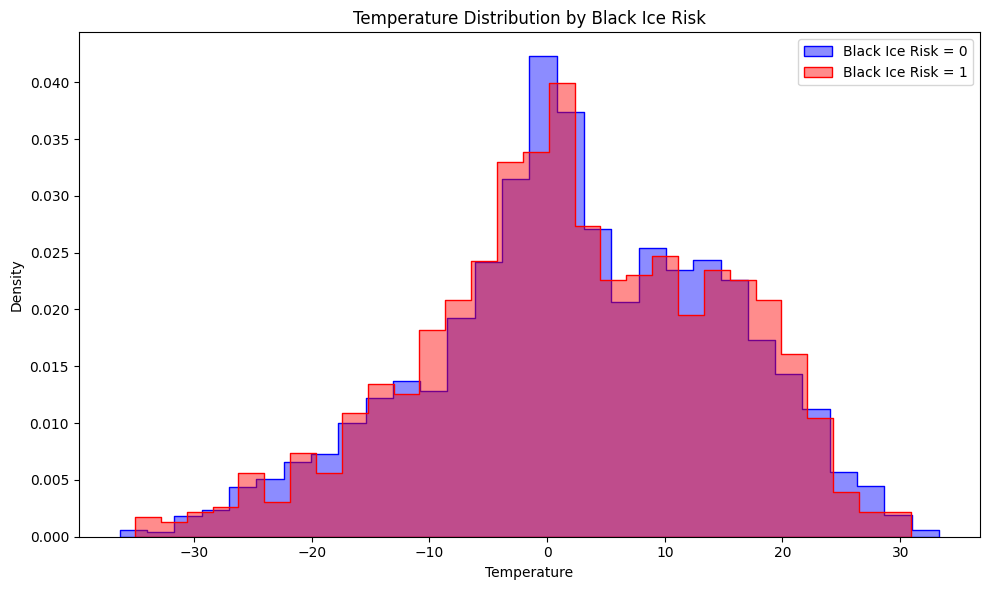

In [ ]:
plt.figure(figsize=(10, 6))

# Black Ice Risk = 0 ka temperature distribution
sns.histplot(
    data=data[data["Black_Ice_Risk"] == 0],
    x="temp",
    color="blue",
    label="Black Ice Risk = 0",
    bins=30,
    stat="density",
    alpha=0.45,
    element="step",
    fill=True
)

# Black Ice Risk = 1 ka temperature distribution
sns.histplot(
    data=data[data["Black_Ice_Risk"] == 1],
    x="temp",
    color="red",
    label="Black Ice Risk = 1",
    bins=30,
    stat="density",
    alpha=0.45,
    element="step",
    fill=True
)

plt.title("Temperature Distribution by Black Ice Risk")
plt.xlabel("Temperature")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

# Observation:
 Both Black Ice Risk groups show a similar temperature distribution, with substantial overlap. This suggests that temperature alone may not clearly distinguish records with and without Black Ice Risk.

# Weather Risk Patterns
Wind Speed vs Risk Label

This graph compares wind-speed distributions between the two risk classes to identify whether wind speed differs across risk levels.

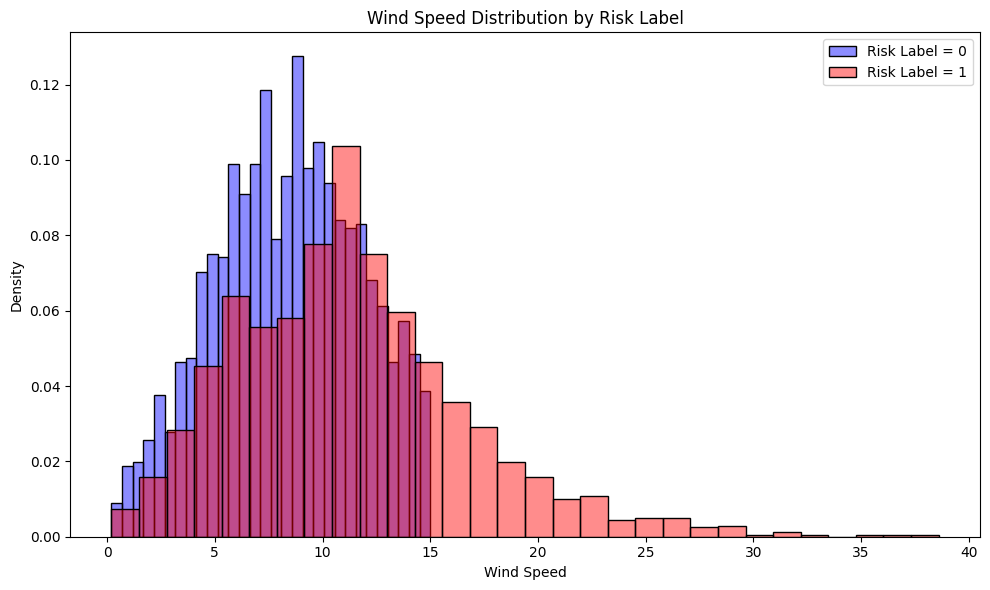

In [ ]:
plt.figure(figsize=(10, 6))

# Risk Label = 0
sns.histplot(
    data=data[data["Risk_Label"] == 0],
    x="wind",
    color="blue",
    label="Risk Label = 0",
    bins=30,
    stat="density",
    alpha=0.45)

# Risk Label = 1
sns.histplot(
    data=data[data["Risk_Label"] == 1],
    x="wind",
    color="red",
    label="Risk Label = 1",
    bins=30,
    stat="density",
    alpha=0.45)

plt.title("Wind Speed Distribution by Risk Label")
plt.xlabel("Wind Speed")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

# Snowfall vs Risk Label
This graph compares snowfall distributions between the two risk classes to see whether snowfall patterns differ with the risk label.

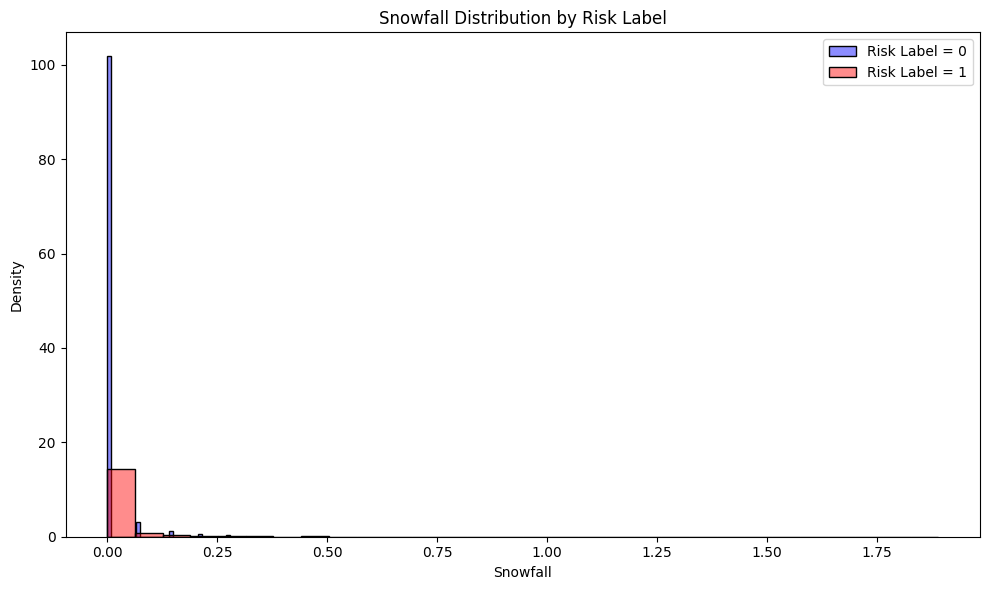

In [ ]:
plt.figure(figsize=(10, 6))

# Risk Label = 0
sns.histplot(
    data=data[data["Risk_Label"] == 0],
    x="snowfall",
    color="blue",
    label="Risk Label = 0",
    bins=30,
    stat="density",
    alpha=0.45
)

# Risk Label = 1
sns.histplot(
    data=data[data["Risk_Label"] == 1],
    x="snowfall",
    color="red",
    label="Risk Label = 1",
    bins=30,
    stat="density",
    alpha=0.45
)

plt.title("Snowfall Distribution by Risk Label")
plt.xlabel("Snowfall")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

# Precipitation vs Risk Label
This graph compares precipitation distributions between the two risk classes to identify possible differences in their weather patterns.

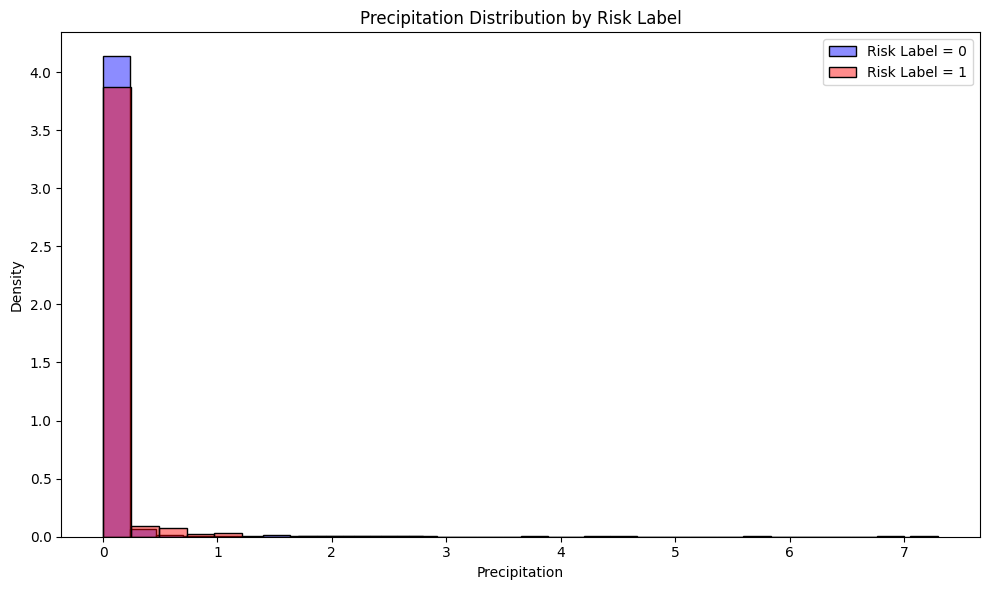

In [ ]:
plt.figure(figsize=(10, 6))

# Risk Label = 0
sns.histplot(
    data=data[data["Risk_Label"] == 0],
    x="precip",
    color="blue",
    label="Risk Label = 0",
    bins=30,
    stat="density",
    alpha=0.45
)

# Risk Label = 1
sns.histplot(
    data=data[data["Risk_Label"] == 1],
    x="precip",
    color="red",
    label="Risk Label = 1",
    bins=30,
    stat="density",
    alpha=0.45
)

plt.title("Precipitation Distribution by Risk Label")
plt.xlabel("Precipitation")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Verify timestamp range without modifying the original dataset
time_check = pd.to_datetime(data["START_DT_UTC"], errors="coerce", utc=True)

print("Earliest Timestamp:", time_check.min())
print("Latest Timestamp:", time_check.max())
print("Invalid Timestamps:", time_check.isna().sum())
print("Total Records:", len(data))

# Monthly Risk Percentage
This graph shows the monthly percentage of records labeled as risk, reducing daily fluctuations and making longer-term patterns easier to see.

/tmp/ipykernel_9225/1353709321.py:9: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  time_data["Month"] = time_data["Timestamp"].dt.to_period("M").astype(str)


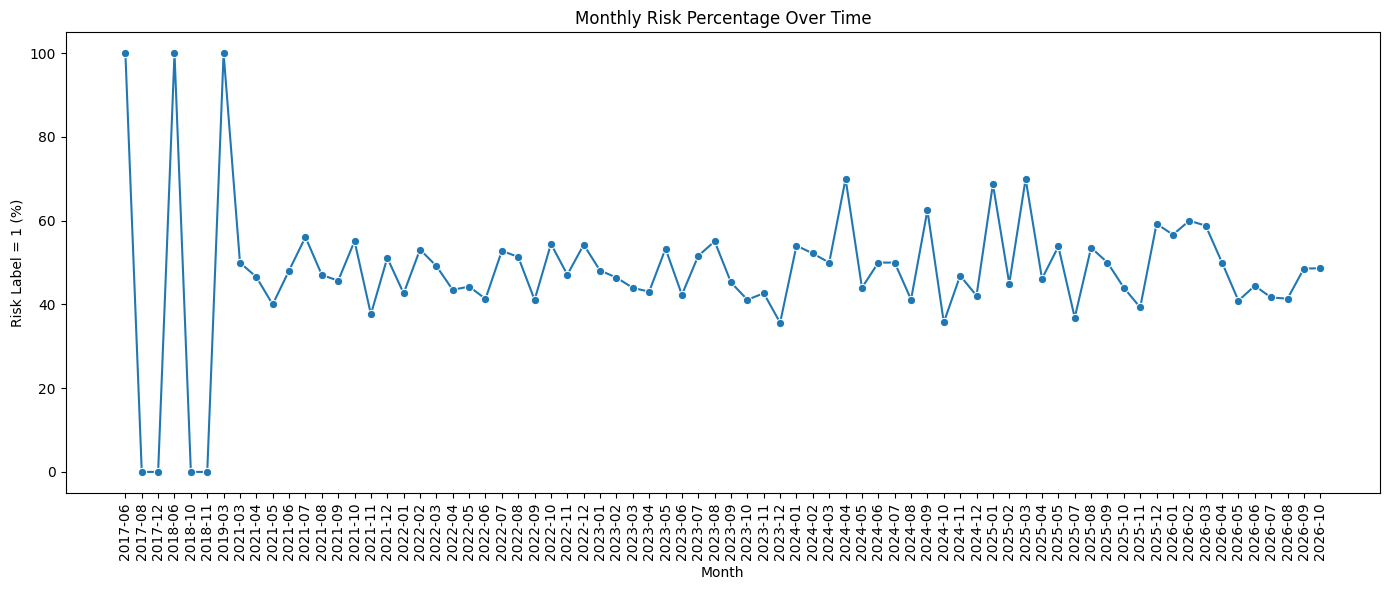

In [ ]:
# Monthly Risk Percentage Over Time
# Create temporary data; original dataset remains unchanged
time_data = pd.DataFrame({
    "Timestamp": pd.to_datetime(data["START_DT_UTC"], errors="coerce", utc=True),
    "Risk_Label": data["Risk_Label"]
})

# Calculate monthly risk percentage
time_data["Month"] = time_data["Timestamp"].dt.to_period("M").astype(str)
monthly_risk = time_data.groupby("Month")["Risk_Label"].mean().mul(100).reset_index(name="Risk_Percentage")

# Plot monthly trend
plt.figure(figsize=(14, 6))
sns.lineplot(data=monthly_risk, x="Month", y="Risk_Percentage", marker="o")

plt.title("Monthly Risk Percentage Over Time")
plt.xlabel("Month")
plt.ylabel("Risk Label = 1 (%)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# Geographical Risk Distribution
This scatter plot shows the geographic distribution of risk and non-risk records using latitude and longitude. It helps identify whether risk records appear concentrated in particular areas.

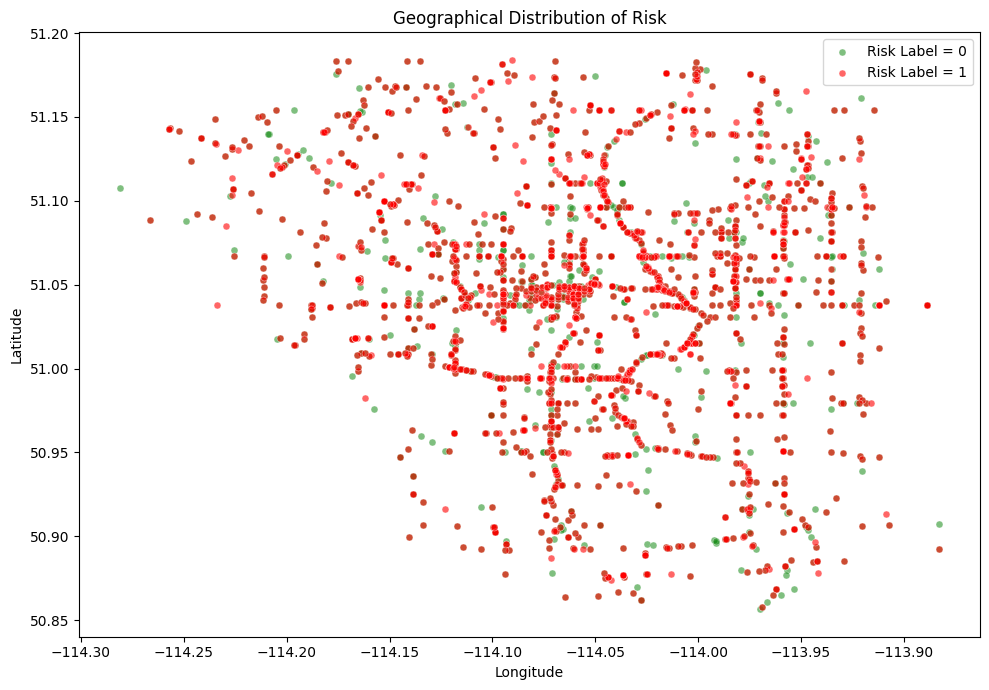

In [ ]:
# Geographical Risk Distribution
plt.figure(figsize=(10, 7))

# Plot locations with Risk_Label = 0
sns.scatterplot(
    data=data[data["Risk_Label"] == 0],
    x="Longitude",
    y="Latitude",
    color="green",
    label="Risk Label = 0",
    alpha=0.5,
    s=25
)

# Plot locations with Risk_Label = 1
sns.scatterplot(
    data=data[data["Risk_Label"] == 1],
    x="Longitude",
    y="Latitude",
    color="red",
    label="Risk Label = 1",
    alpha=0.6,
    s=25
)

plt.title("Geographical Distribution of Risk")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.tight_layout()
plt.show()

# Risk Zone vs Risk Label
This grouped count plot compares the number of records for each Risk_Label across the different Risk_Zone categories.

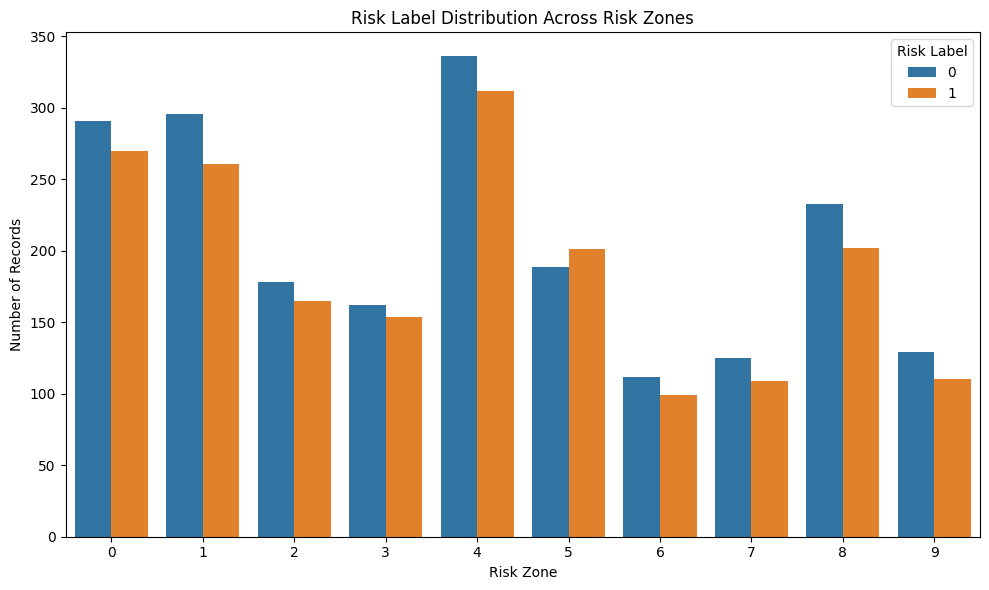

In [ ]:
# Risk Zone vs Risk Label
plt.figure(figsize=(10, 6))

# Compare risk labels across geographical zones
sns.countplot(
    data=data,
    x="Risk_Zone",
    hue="Risk_Label"
)

plt.title("Risk Label Distribution Across Risk Zones")
plt.xlabel("Risk Zone")
plt.ylabel("Number of Records")
plt.legend(title="Risk Label")
plt.tight_layout()
plt.show()

# Geographical Distribution of Black Ice Risk
This scatter plot displays the geographical locations of records in each Black Ice Risk category, helping identify possible spatial patterns.

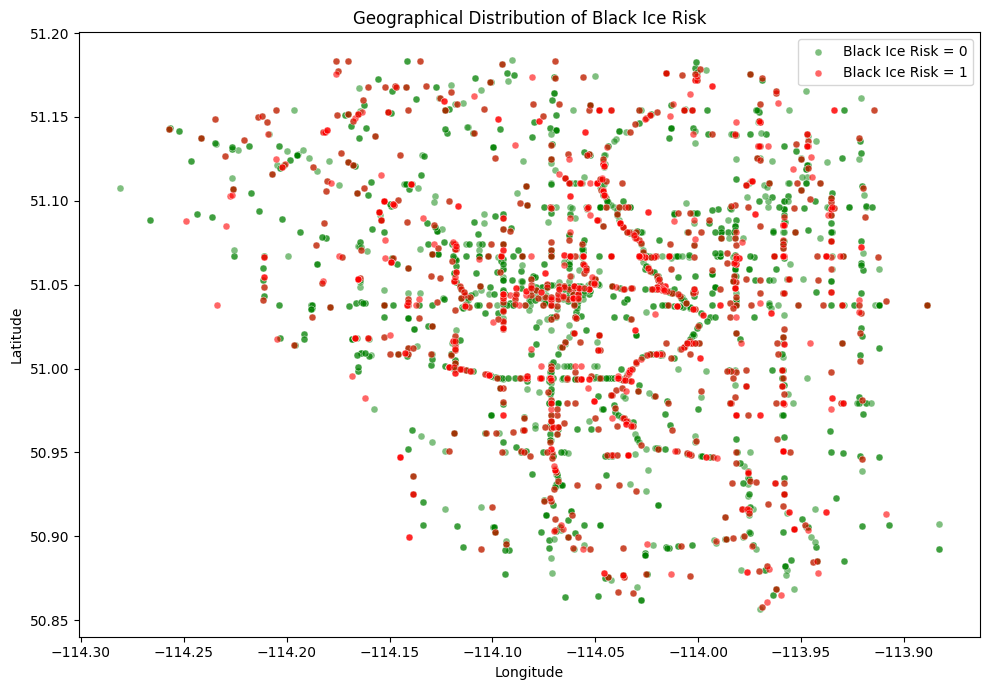

In [ ]:
# Geographical Distribution of Black Ice Risk
plt.figure(figsize=(10, 7))

# Plot records where Black Ice Risk = 0
sns.scatterplot(
    data=data[data["Black_Ice_Risk"] == 0],
    x="Longitude",
    y="Latitude",
    color="green",
    label="Black Ice Risk = 0",
    alpha=0.5,
    s=25
)

# Plot records where Black Ice Risk = 1
sns.scatterplot(
    data=data[data["Black_Ice_Risk"] == 1],
    x="Longitude",
    y="Latitude",
    color="red",
    label="Black Ice Risk = 1",
    alpha=0.6,
    s=25
)

plt.title("Geographical Distribution of Black Ice Risk")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.tight_layout()
plt.show()

# Feature Engineering
## Date-Time Feature Analysis
This cell extracts year, month, day, hour, and day-of-week features from the timestamp. It stores them separately and checks their ranges without changing the original dataset

In [ ]:
# Date-Time Feature Analysis
# Convert timestamps into a separate Series; original data remains unchanged
timestamp = pd.to_datetime(
    data["START_DT_UTC"],
    errors="coerce",
    utc=True
)
# Create a separate feature DataFrame
time_features = pd.DataFrame(index=data.index)

# Extract date-time features
time_features["Year"] = timestamp.dt.year
time_features["Month"] = timestamp.dt.month
time_features["Day"] = timestamp.dt.day
time_features["Hour"] = timestamp.dt.hour
time_features["DayOfWeek"] = timestamp.dt.dayofweek

# Display a sample of the generated features
print("Generated Time Features:")
display(time_features.head(10))

# Validate extracted feature ranges
print("\nFeature Validation:")
print("Year Range:", time_features["Year"].min(), "to", time_features["Year"].max())
print("Month Range:", time_features["Month"].min(), "to", time_features["Month"].max())
print("Hour Range:", time_features["Hour"].min(), "to", time_features["Hour"].max())
print("Missing Timestamp Values:", timestamp.isna().sum())

Generated Time Features:


,Year,Month,Day,Hour,DayOfWeek
0,2026,9,18,21,4
1,2026,9,18,22,4
2,2026,9,18,22,4
3,2026,9,18,23,4
4,2026,9,19,0,5
5,2026,9,19,0,5
6,2026,9,19,0,5
7,2026,9,19,1,5
8,2026,9,19,1,5
9,2026,9,19,3,5



Feature Validation:
Year Range: 2017 to 2026
Month Range: 1 to 12
Hour Range: 0 to 23
Missing Timestamp Values: 0


# Existing Feature Analysis
This cell identifies existing numerical and categorical features and lists the potential prediction targets

In [ ]:
# Existing Feature Analysis
# Identify numerical columns
numerical_features = data.select_dtypes(include="number").columns.tolist()

# Identify categorical columns
categorical_features = data.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Display existing features
print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nPotential Target Columns:")
print(["Risk_Label", "Black_Ice_Risk"])

print("\nDataset Shape:", data.shape)

Numerical Features:
['temp', 'snowfall', 'precip', 'wind', 'Latitude', 'Longitude', 'Risk_Label', 'Wind_Chill', 'Is_Freezing', 'Severe_Weather', 'Risk_Zone', 'Zone_Weather_Risk', 'Is_Night', 'Is_RushHour', 'Visibility_m', 'Snow_Depth_m', 'Surface_Pressure_hPa', 'Black_Ice_Risk']

Categorical Features:
['START_DT_UTC']

Potential Target Columns:
['Risk_Label', 'Black_Ice_Risk']

Dataset Shape: (3934, 19)


This step examines the available values and distributions of the candidate target columns so we can decide which prediction task is appropriate.

In [ ]:
# Prediction Target Analysis
# Check whether the candidate target columns exist
candidate_targets = ["Risk_Label", "Black_Ice_Risk"]

for column in candidate_targets:
    print(f"\nColumn: {column}")

    if column in data.columns:
        print("Data Type:", data[column].dtype)
        print("Unique Values:", data[column].nunique())
        print("Value Counts:")
        print(data[column].value_counts(dropna=False))
    else:
        print("Column not found in dataset.")

# Confirm that the original dataset remains unchanged
print("\nDataset Shape:", data.shape)



Column: Risk_Label
Data Type: int64
Unique Values: 2
Value Counts:
Risk_Label
0    2051
1    1883
Name: count, dtype: int64

Column: Black_Ice_Risk
Data Type: float64
Unique Values: 2
Value Counts:
Black_Ice_Risk
0.0    2885
1.0    1049
Name: count, dtype: int64

Dataset Shape: (3934, 19)


## Define and validate the 15 selected input features for predicting Risk_Label

In [ ]:
# Define Input Features and Prediction Target
# Define the target column
target_column = "Risk_Label"
# Define the selected input features
input_features = [
    'temp', 'snowfall', 'precip', 'wind', 'Wind_Chill',
    'Is_Freezing', 'Severe_Weather', 'Risk_Zone', 'Zone_Weather_Risk',
    'Is_Night', 'Is_RushHour', 'Visibility_m', 'Snow_Depth_m',
    'Surface_Pressure_hPa', 'Black_Ice_Risk']

# Validate that all selected columns exist
missing_features = [
    column for column in input_features
    if column not in data.columns]

if missing_features:
    print("Columns not found:", missing_features)
else:
    print("All selected input features exist.")
    print("\nInput Features:")
    print(input_features)
    print("\nTotal Input Features:", len(input_features))
    print("Prediction Target:", target_column)
    print("\nTarget Distribution:")
    print(data[target_column].value_counts())
    print("\nOriginal Dataset Shape:", data.shape)

All selected input features exist.

Input Features:
['temp', 'snowfall', 'precip', 'wind', 'Wind_Chill', 'Is_Freezing', 'Severe_Weather', 'Risk_Zone', 'Zone_Weather_Risk', 'Is_Night', 'Is_RushHour', 'Visibility_m', 'Snow_Depth_m', 'Surface_Pressure_hPa', 'Black_Ice_Risk']

Total Input Features: 15
Prediction Target: Risk_Label

Target Distribution:
Risk_Label
0    2051
1    1883
Name: count, dtype: int64

Original Dataset Shape: (3934, 19)


## Finalize the selected 15 input features as X and Risk_Label as y, while preserving the original dataset.

In [ ]:
# Finalize Input Features and Target
# Define the 15 selected input features
input_features = [
    'temp', 'snowfall', 'precip', 'wind', 'Wind_Chill',
    'Is_Freezing', 'Severe_Weather', 'Risk_Zone', 'Zone_Weather_Risk',
    'Is_Night', 'Is_RushHour', 'Visibility_m', 'Snow_Depth_m',
    'Surface_Pressure_hPa', 'Black_Ice_Risk'
]

# Create model inputs and prediction target
X = data[input_features]
y = data['Risk_Label']

# Train-Test Split
## Split the master feature dataset and target into training (80%) and testing (20%) sets while preserving target class proportions.

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y)

In [ ]:
# Check the shapes after splitting
print("X_train Shape:", X_train.shape)
print("X_test Shape:", X_test.shape)
print("y_train Shape:", y_train.shape)
print("y_test Shape:", y_test.shape)

X_train Shape: (3147, 15)
X_test Shape: (787, 15)
y_train Shape: (3147,)
y_test Shape: (787,)


# Model Training
# Decision Tree Classifier
Train a Decision Tree classifier and evaluate its accuracy on the test dataset.

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

In [ ]:
# Decision Tree Model Training and Accuracy
#Initialize and train the model
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)
# Generate predictions
y_pred_dt = dt_model.predict(X_test)
# Calculate evaluation metrics
dt_accuracy = accuracy_score(y_test, y_pred_dt)
dt_precision = precision_score(y_test, y_pred_dt, zero_division=0)
dt_recall = recall_score(y_test, y_pred_dt, zero_division=0)
dt_f1 = f1_score(y_test, y_pred_dt, zero_division=0)
# Display results
print("Decision Tree Evaluation")
print(f"Accuracy  : {dt_accuracy * 100:.2f}%")
print(f"Precision : {dt_precision * 100:.2f}%")
print(f"Recall    : {dt_recall * 100:.2f}%")
print(f"F1-Score  : {dt_f1 * 100:.2f}%")

Decision Tree Evaluation
Accuracy  : 63.53%
Precision : 61.60%
Recall    : 63.40%
F1-Score  : 62.48%


# Decision Tree Hyperparameter Tuning
This code uses RandomizedSearchCV with five-fold cross-validation to find suitable Decision Tree hyperparameters based on F1-score and evaluates the tuned model on the test dataset.

In [ ]:
# Decision Tree Hyperparameter Tuning
# Define hyperparameter combinations
dt_param_grid = {
    "criterion": ["gini", "entropy", "log_loss"],
    "max_depth": [None, 5, 10, 15, 20, 30],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": [None, "sqrt", "log2"]
}

# Search for the best hyperparameters
dt_search = RandomizedSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_distributions=dt_param_grid,
    n_iter=30,
    scoring="f1",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Train and tune the model
dt_search.fit(X_train, y_train)

# Store the best tuned model
dt_model_tuned = dt_search.best_estimator_

# Generate predictions
y_pred_dt_tuned = dt_model_tuned.predict(X_test)

# Evaluate model performance
print("Best Parameters:", dt_search.best_params_)
print(f"Accuracy  : {accuracy_score(y_test, y_pred_dt_tuned) * 100:.2f}%")
print(f"Precision : {precision_score(y_test, y_pred_dt_tuned, zero_division=0) * 100:.2f}%")
print(f"Recall    : {recall_score(y_test, y_pred_dt_tuned, zero_division=0) * 100:.2f}%")
print(f"F1-Score  : {f1_score(y_test, y_pred_dt_tuned, zero_division=0) * 100:.2f}%")

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Parameters: {'min_samples_split': 20, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 5, 'criterion': 'log_loss'}
Accuracy  : 65.18%
Precision : 59.63%
Recall    : 84.62%
F1-Score  : 69.96%


# Random Forest
Train Random Forest and evaluate its classification performance using the same test set and four metrics.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
# Random Forest: Training and Evaluation
# Initialize and train the model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)
# Generate predictions
y_pred_rf = rf_model.predict(X_test)
# Calculate evaluation metrics
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf, zero_division=0)
rf_recall = recall_score(y_test, y_pred_rf, zero_division=0)
rf_f1 = f1_score(y_test, y_pred_rf, zero_division=0)
# Display results
print("Random Forest Evaluation")
print(f"Accuracy  : {rf_accuracy * 100:.2f}%")
print(f"Precision : {rf_precision * 100:.2f}%")
print(f"Recall    : {rf_recall * 100:.2f}%")
print(f"F1-Score  : {rf_f1 * 100:.2f}%")

Random Forest Evaluation
Accuracy  : 64.80%
Precision : 62.95%
Recall    : 64.46%
F1-Score  : 63.70%


# Random Forest Hyperparameter Tuning
This code tunes the Random Forest model by searching different tree counts, tree depths, split settings, and class-weight options. It selects the best configuration using five-fold cross-validation and F1-score.

In [ ]:
# Random Forest Hyperparameter Tuning
# Define hyperparameter combinations
rf_param_grid = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"],
    "class_weight": [None, "balanced"]
}

# Search for the best hyperparameters
rf_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ),
    param_distributions=rf_param_grid,
    n_iter=25,
    scoring="f1",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Train and tune the model
rf_search.fit(X_train, y_train)

# Store the best tuned model
rf_model_tuned = rf_search.best_estimator_

# Generate predictions
y_pred_rf_tuned = rf_model_tuned.predict(X_test)

# Evaluate model performance
print("Best Parameters:", rf_search.best_params_)
print(f"Accuracy  : {accuracy_score(y_test, y_pred_rf_tuned) * 100:.2f}%")
print(f"Precision : {precision_score(y_test, y_pred_rf_tuned, zero_division=0) * 100:.2f}%")
print(f"Recall    : {recall_score(y_test, y_pred_rf_tuned, zero_division=0) * 100:.2f}%")
print(f"F1-Score  : {f1_score(y_test, y_pred_rf_tuned, zero_division=0) * 100:.2f}%")

Fitting 5 folds for each of 25 candidates, totalling 125 fits
Best Parameters: {'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': 'log2', 'max_depth': None, 'class_weight': 'balanced'}
Accuracy  : 66.45%
Precision : 63.61%
Recall    : 70.03%
F1-Score  : 66.67%


# XGBoost
Train XGBoost and evaluate its performance using accuracy, precision, recall, and F1-score.

In [ ]:
from xgboost import XGBClassifier

In [ ]:
# XGBoost: Training and Evaluation
# Initialize and train the model
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)
xgb_model.fit(X_train, y_train)
# Generate predictions
y_pred_xgb = xgb_model.predict(X_test)
# Calculate evaluation metrics
xgb_accuracy = accuracy_score(y_test, y_pred_xgb)
xgb_precision = precision_score(y_test, y_pred_xgb, zero_division=0)
xgb_recall = recall_score(y_test, y_pred_xgb, zero_division=0)
xgb_f1 = f1_score(y_test, y_pred_xgb, zero_division=0)
# Display results
print("XGBoost Evaluation")
print(f"Accuracy  : {xgb_accuracy * 100:.2f}%")
print(f"Precision : {xgb_precision * 100:.2f}%")
print(f"Recall    : {xgb_recall * 100:.2f}%")
print(f"F1-Score  : {xgb_f1 * 100:.2f}%")

XGBoost Evaluation
Accuracy  : 66.71%
Precision : 64.71%
Recall    : 67.11%
F1-Score  : 65.89%


# XGBoost Hyperparameter Tuning
This code tunes XGBoost by testing different boosting rounds, learning rates, tree depths, sampling settings, and regularization values. Five-fold cross-validation selects the configuration with the best F1-score.

In [ ]:
# XGBoost Hyperparameter Tuning
# Define hyperparameter combinations
xgb_param_grid = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [3, 4, 5, 6, 8, 10],
    "learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "min_child_weight": [1, 3, 5, 7],
    "gamma": [0, 0.1, 0.2, 0.5],
    "reg_lambda": [1, 2, 5, 10]
}

# Search for the best hyperparameters
xgb_search = RandomizedSearchCV(
    estimator=XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    ),
    param_distributions=xgb_param_grid,
    n_iter=30,
    scoring="f1",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Train and tune the model
xgb_search.fit(X_train, y_train)

# Store the best tuned model
xgb_model_tuned = xgb_search.best_estimator_

# Generate predictions
y_pred_xgb_tuned = xgb_model_tuned.predict(X_test)

# Evaluate model performance
print("Best Parameters:", xgb_search.best_params_)
print(f"Accuracy  : {accuracy_score(y_test, y_pred_xgb_tuned) * 100:.2f}%")
print(f"Precision : {precision_score(y_test, y_pred_xgb_tuned, zero_division=0) * 100:.2f}%")
print(f"Recall    : {recall_score(y_test, y_pred_xgb_tuned, zero_division=0) * 100:.2f}%")
print(f"F1-Score  : {f1_score(y_test, y_pred_xgb_tuned, zero_division=0) * 100:.2f}%")

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Parameters: {'subsample': 0.7, 'reg_lambda': 2, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.1, 'gamma': 0.1, 'colsample_bytree': 1.0}
Accuracy  : 62.64%
Precision : 60.45%
Recall    : 63.66%
F1-Score  : 62.02%


# Model Performance Comparison Graph
This code compares Decision Tree, Random Forest, and XGBoost using Accuracy, Precision, and Recall. It displays the results in a grouped bar chart and a table

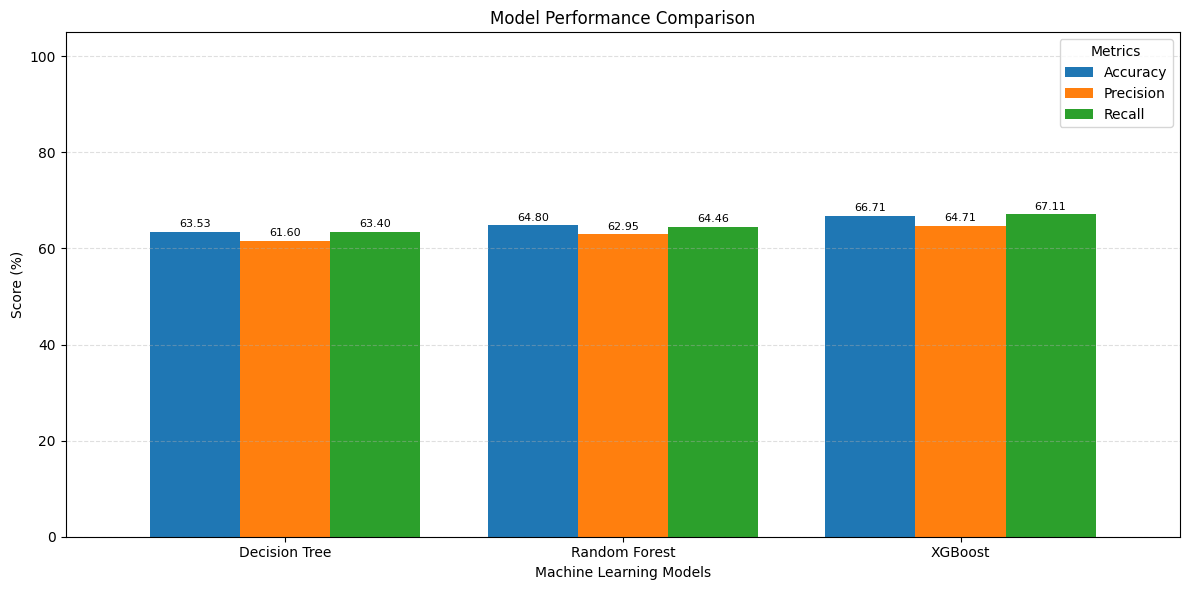

,Accuracy,Precision,Recall
Model,,,
Decision Tree,63.53,61.60,63.40
Random Forest,64.80,62.95,64.46
XGBoost,66.71,64.71,67.11


In [ ]:
# Model Performance Comparison: Decision Tree, Random Forest, XGBoost

# Train Decision Tree
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)

# Train Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

# Use the already-trained XGBoost model
y_pred_xgb = xgb_model.predict(X_test)

# Collect predictions from three models
models_predictions = {
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "XGBoost": y_pred_xgb
}

# Calculate evaluation metrics
metrics_data = []

for model_name, predictions in models_predictions.items():
    metrics_data.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions) * 100,
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ) * 100,
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ) * 100
    })

metrics_df = pd.DataFrame(metrics_data).set_index("Model")

# Plot performance comparison
ax = metrics_df.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Model Performance Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Score (%)")
plt.ylim(0, 105)
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.grid(axis="y", linestyle="--", alpha=0.4)

# Display metric values above each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=2, fontsize=8)

plt.tight_layout()
plt.show()

# Display exact metric values
display(metrics_df.round(2))

# Tuned Models Performance Comparison
This code compares the tuned Decision Tree and Random Forest models using four evaluation metrics. It displays a grouped bar chart and a table containing their exact scores.

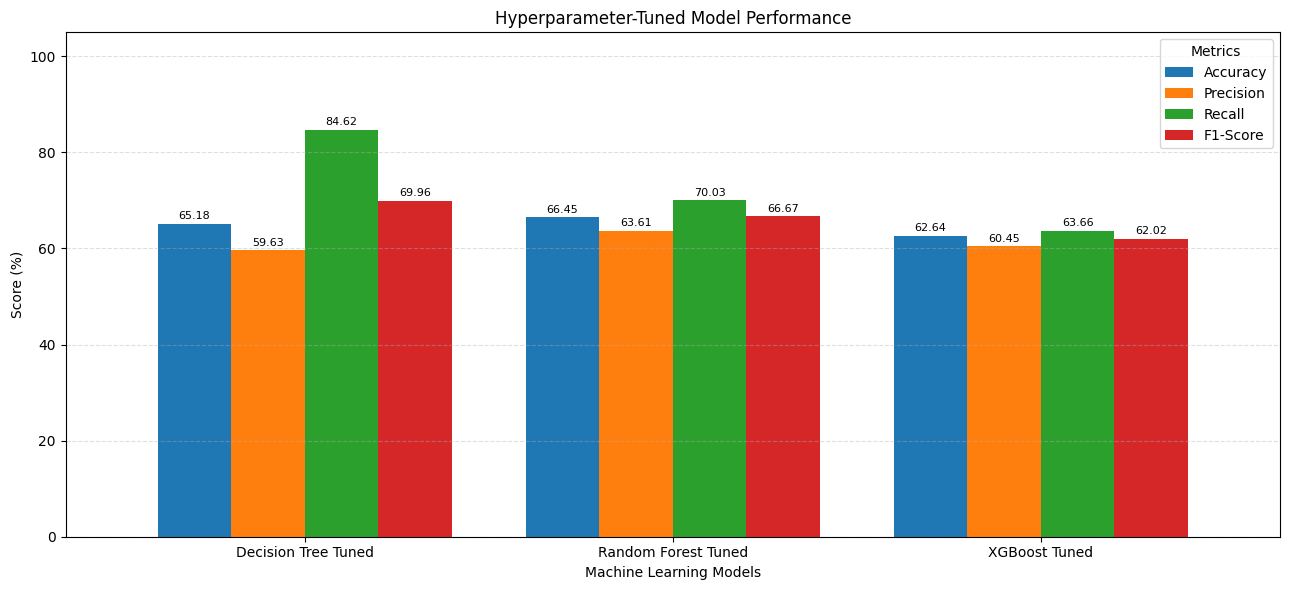

,Accuracy,Precision,Recall,F1-Score
Model,,,,
Decision Tree Tuned,65.18,59.63,84.62,69.96
Random Forest Tuned,66.45,63.61,70.03,66.67
XGBoost Tuned,62.64,60.45,63.66,62.02


In [ ]:
# Compare Hyperparameter-Tuned Models
# Collect predictions from tuned models
tuned_predictions = {
    "Decision Tree Tuned": y_pred_dt_tuned,
    "Random Forest Tuned": y_pred_rf_tuned,
    "XGBoost Tuned": y_pred_xgb_tuned
}

# Calculate evaluation metrics
tuned_metrics = []

for model_name, predictions in tuned_predictions.items():
    tuned_metrics.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions) * 100,
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ) * 100,
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ) * 100,
        "F1-Score": f1_score(
            y_test, predictions, zero_division=0
        ) * 100
    })

# Create performance comparison table
tuned_metrics_df = pd.DataFrame(
    tuned_metrics
).set_index("Model")

# Plot performance comparison
ax = tuned_metrics_df.plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)

plt.title("Hyperparameter-Tuned Model Performance")
plt.xlabel("Machine Learning Models")
plt.ylabel("Score (%)")
plt.ylim(0, 105)
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.grid(axis="y", linestyle="--", alpha=0.4)

# Display metric values above each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        padding=2,
        fontsize=8
    )

plt.tight_layout()
plt.show()

# Display exact metric values
display(tuned_metrics_df.round(2))

# Stacking Ensemble: XGBoost + CatBoost + LightGBM
Train a stacking ensemble of LightGBM, CatBoost, and XGBoost, using Logistic Regression as the final estimator, and evaluate its classification performance on the held-out test set.

In [ ]:
!pip -q install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 5.4 MB/s eta 0:00:00


In [ ]:
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
import xgboost as xgb
import catboost as cb
import lightgbm as lgb

In [ ]:
# Stacking Ensemble: XGBoost + CatBoost + LightGBM
# LightGBM Model
model_lgb = lgb.LGBMClassifier(
    n_estimators=500,
    max_depth=7,
    learning_rate=0.03,
    random_state=42,
    verbosity=-1)

# CatBoost Model
model_cat = cb.CatBoostClassifier(
    iterations=500,
    depth=6,
    learning_rate=0.03,
    random_seed=42,
    verbose=0,
    allow_writing_files=False)

# XGBoost Model
model_xgb = xgb.XGBClassifier(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.03,
    random_state=42,
    eval_metric="logloss",
    verbosity=0)

# Stacking Ensemble: Final Master Model
stacking_master = StackingClassifier(
    estimators=[
        ("lgb", model_lgb),
        ("cat", model_cat),
        ("xgb", model_xgb)],
    final_estimator=LogisticRegression(max_iter=1000),
    cv=5,
    n_jobs=-1)

# Train the Stacking Model
stacking_master.fit(X_train, y_train)

# Generate Test Predictions
master_preds = stacking_master.predict(X_test)
# Calculate Performance Metrics
master_accuracy = accuracy_score(y_test, master_preds)
master_precision = precision_score(
    y_test, master_preds, zero_division=0)
master_recall = recall_score(
    y_test, master_preds, zero_division=0)
master_f1 = f1_score(
    y_test, master_preds, zero_division=0)

# Display Final Results
print("=== STACKING MASTER MODEL PERFORMANCE ===")
print(f"Accuracy  : {master_accuracy * 100:.2f}%")
print(f"Precision : {master_precision * 100:.2f}%")
print(f"Recall    : {master_recall * 100:.2f}%")
print(f"F1-Score  : {master_f1 * 100:.2f}%")

print("\nClassification Report:\n")
print(
    classification_report(
        y_test,
        master_preds,
        zero_division=0))

=== STACKING MASTER MODEL PERFORMANCE ===
Accuracy  : 66.45%
Precision : 64.45%
Recall    : 66.84%
F1-Score  : 65.62%

Classification Report:

              precision    recall  f1-score   support

           0       0.68      0.66      0.67       410
           1       0.64      0.67      0.66       377

    accuracy                           0.66       787
   macro avg       0.66      0.66      0.66       787
weighted avg       0.67      0.66      0.66       787



# Model Performance Comparison Graph
Compare the test-set accuracy, precision, and recall of four models using a grouped bar chart and a results table

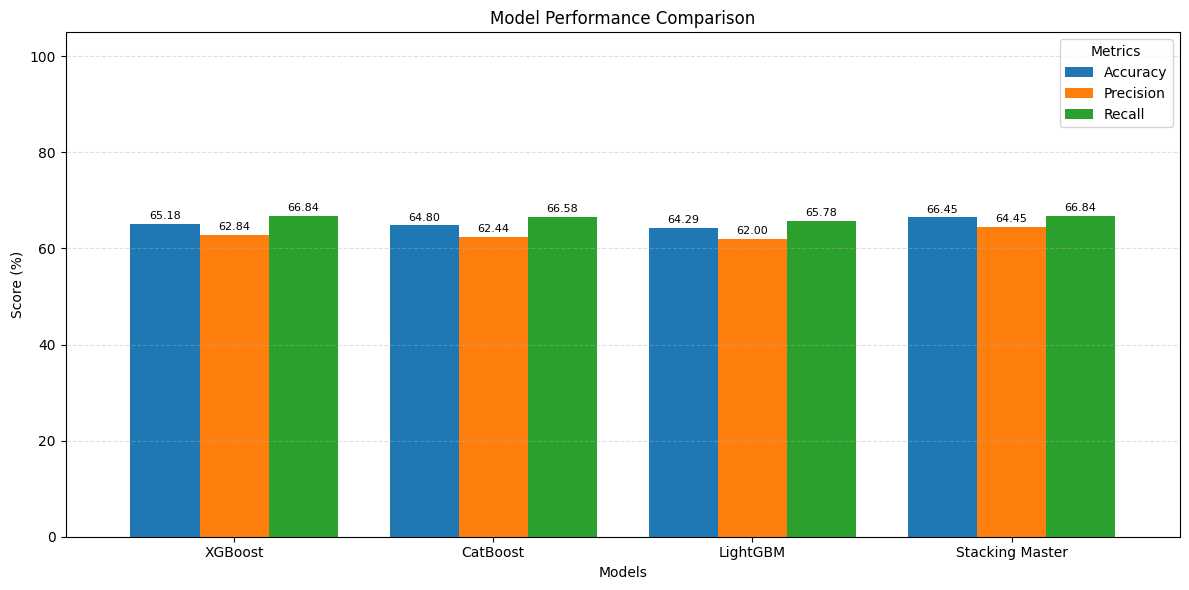

,Accuracy,Precision,Recall
Model,,,
XGBoost,65.18,62.84,66.84
CatBoost,64.80,62.44,66.58
LightGBM,64.29,62.00,65.78
Stacking Master,66.45,64.45,66.84


In [ ]:
# Model Performance Comparison Graph
# Get predictions from the fitted models inside the stacking model
fitted_models = dict(stacking_master.named_estimators_)

models_predictions = {
    "XGBoost": (y_test, fitted_models["xgb"].predict(X_test)),
    "CatBoost": (y_test, fitted_models["cat"].predict(X_test).ravel()),
    "LightGBM": (y_test, fitted_models["lgb"].predict(X_test)),
    "Stacking Master": (y_test, stacking_master.predict(X_test))
}

# Calculate evaluation metrics
metrics_data = []

for model_name, (actual, predicted) in models_predictions.items():
    metrics_data.append({
        "Model": model_name,
        "Accuracy": accuracy_score(actual, predicted) * 100,
        "Precision": precision_score(
            actual, predicted, zero_division=0
        ) * 100,
        "Recall": recall_score(
            actual, predicted, zero_division=0
        ) * 100
    })

metrics_df = pd.DataFrame(metrics_data).set_index("Model")

# Plot model comparison
ax = metrics_df.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Model Performance Comparison")
plt.xlabel("Models")
plt.ylabel("Score (%)")
plt.ylim(0, 105)
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.grid(axis="y", linestyle="--", alpha=0.4)

# Add score labels to the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=2, fontsize=8)

plt.tight_layout()
plt.show()

# Display exact scores
display(metrics_df.round(2))


# Deep Learning Models


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout

#Set reproducibility

In [ ]:
# Set reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Scale features using training data only

In [ ]:
from sklearn.preprocessing import StandardScaler

In [ ]:
lstm_scaler = StandardScaler()
X_train_scaled = lstm_scaler.fit_transform(X_train)
X_test_scaled = lstm_scaler.transform(X_test)

# Reshape tabular data for LSTM:

In [ ]:
# 15 input features are treated as 15 positions in one sequence.
X_train_lstm = X_train_scaled.reshape(
    X_train_scaled.shape[0], X_train_scaled.shape[1], 1)

X_test_lstm = X_test_scaled.reshape(
    X_test_scaled.shape[0], X_test_scaled.shape[1], 1)

# Build LSTM classifier

In [ ]:
# Build LSTM classifier
lstm_model = Sequential([
    Input(shape=(X_train_lstm.shape[1], 1)),
    LSTM(64, activation="tanh"),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(1, activation="sigmoid")
])

# Compile model

In [ ]:
# Compile model
lstm_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Training model

In [ ]:
# Train model
history_lstm = lstm_model.fit(
    X_train_lstm,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

# Generate predictions

In [ ]:
# Generate predictions
y_pred_lstm_prob = lstm_model.predict(X_test_lstm, verbose=0)
y_pred_lstm = (y_pred_lstm_prob.ravel() >= 0.5).astype(int)

# Evaluate performance

In [ ]:
# Evaluate performance
lstm_accuracy = accuracy_score(y_test, y_pred_lstm)
lstm_precision = precision_score(
    y_test, y_pred_lstm, zero_division=0
)
lstm_recall = recall_score(
    y_test, y_pred_lstm, zero_division=0
)
lstm_f1 = f1_score(
    y_test, y_pred_lstm, zero_division=0
)

print("=== LSTM MODEL PERFORMANCE ===")
print(f"Accuracy  : {lstm_accuracy * 100:.2f}%")
print(f"Precision : {lstm_precision * 100:.2f}%")
print(f"Recall    : {lstm_recall * 100:.2f}%")
print(f"F1-Score  : {lstm_f1 * 100:.2f}%")

# XGBoost Model Saving

In [ ]:
# Save XGBoost Model

xgb_model.save_model("arctic_master_final_model_v3.pkl")
print("XGBoost model saved successfully as xgboost_model.pkl")